In [1]:
# ============================================================================
# IEEE ACCESS PAPER: HiENBERT - Hybrid Indic-English BERT for Multi-Task 
# Complaint Classification - OPTIMIZED VERSION
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP - OPTIMIZED
# ============================================================================

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    torch.backends.cudnn.benchmark = True
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ============================================================================
# CELL 2: OPTIMIZED CONFIGURATION - FASTER TRAINING
# ============================================================================

class Config:
    """Optimized configuration settings for HiENBERT training"""
    
    # =========================================================================
    # BASE MODEL
    # =========================================================================
    BASE_MODEL = 'xlm-roberta'
    XLMBERT_PATH = "xlm-roberta-base"
    
    # =========================================================================
    # PROJECT ROOT DIRECTORY
    # =========================================================================
    PROJECT_DIR = os.getcwd()
    
    # =========================================================================
    # INPUT DATASET DIRECTORY
    # =========================================================================
    DATA_DIR = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")

    
    # =========================================================================
    # OUTPUT DIRECTORY
    # =========================================================================
    BASE_DIR = os.path.join(PROJECT_DIR, "hienbert_results_CommonDataset")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    LOG_DIR = os.path.join(BASE_DIR, "logs")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
    SHAP_DIR = os.path.join(BASE_DIR, "shap_explanations")
    
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, LOG_DIR,
                     RESULTS_DIR, CHECKPOINT_DIR, SHAP_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    SHAP_DIR = os.path.join(
    RESULTS_DIR,
    "shap_explanations"
)
    # =========================================================================
    # OPTIMIZED TRAINING PARAMETERS - FASTER
    # =========================================================================
    MAX_LENGTH = 128
    BATCH_SIZE = 32  # Increased for faster training
    EPOCHS = 15      # Reduced epochs - early stopping will handle
    LEARNING_RATE = 2e-5  # Slightly higher for faster convergence
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    GRADIENT_ACCUMULATION_STEPS = 1  # Effective batch size = 64 * 2 = 128
    WARMUP_RATIO = 0.1
    
    # =========================================================================
    # OPTIMIZED TRAINING SETTINGS
    # =========================================================================
    USE_AMP = True
    NUM_WORKERS = 4  # For faster data loading
    PIN_MEMORY = True
    
    # =========================================================================
    # DEVICE
    # =========================================================================
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42
    
    # =========================================================================
    # HUGGING FACE TOKEN
    # =========================================================================
    HF_TOKEN = os.getenv("HF_TOKEN")


def get_model_path():
    return Config.XLMBERT_PATH


print("=" * 80)
print("OPTIMIZED HIENBERT CONFIGURATION")
print("=" * 80)
print(f"\n[BATCH SIZE] {Config.BATCH_SIZE} (Effective: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS})")
print(f"[EPOCHS] {Config.EPOCHS}")
print(f"[LEARNING RATE] {Config.LEARNING_RATE}")
print(f"[NUM WORKERS] {Config.NUM_WORKERS}")
print(f"[DEVICE] {Config.DEVICE}")
print("=" * 80)

OPTIMIZED HIENBERT CONFIGURATION

[BATCH SIZE] 32 (Effective: 32)
[EPOCHS] 15
[LEARNING RATE] 2e-05
[NUM WORKERS] 4
[DEVICE] cuda


In [3]:
# ============================================================================
# CELL 3: OPTIMIZED DATA LOADING
# ============================================================================

class OptimizedDataLoader:
    """Load and analyze balanced dataset - OPTIMIZED"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
    
    def load_data(self):
        print("Loading datasets...")
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        print(f"Train: {len(self.train_df)}, Dev: {len(self.dev_df)}, Test: {len(self.test_df)}")
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_distribution(self, df, label_col, title=""):
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        print(f"\n{'='*60}")
        print(f"Class Distribution - {title}")
        print(f"{'='*60}")
        for cls, count in class_counts.items():
            print(f"  {cls}: {count} ({class_percentages[cls]:.2f}%)")
        return class_counts
    
    def analyze_all(self):
        self.load_data()
        print("\n" + "="*80)
        print("DATASET ANALYSIS")
        print("="*80)
        self.analyze_distribution(self.train_df, 'primary_category', 'Primary Categories')
        self.analyze_distribution(self.train_df, 'Severity', 'Severity')
        return self.train_df, self.dev_df, self.test_df

# Load data
data_loader = OptimizedDataLoader()
train_df, dev_df, test_df = data_loader.load_data()

Loading datasets...
Train: 14165, Dev: 3035, Test: 3036


In [4]:
# ============================================================================
# CELL 4: OPTIMIZED DATA PREPROCESSING
# ============================================================================

class OptimizedPreprocessor:
    """Optimized data preprocessing with efficient text handling"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def rename_columns(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        return df
    
    def preprocess_text(self, df):
        df = self.rename_columns(df)
        
        # Fill NaN values efficiently
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        # Combine text efficiently
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("\nPreparing labels...")
        
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary: {len(self.le_primary.classes_)}, "
              f"Subcat: {len(self.le_subcat.classes_)}, "
              f"Severity: {len(self.le_severity.classes_)}")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("\nPreprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"\nFinal: Train {len(train_df)}, Dev {len(dev_df)}, Test {len(test_df)}")
        return train_df, dev_df, test_df

# Process data
preprocessor = OptimizedPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)
print("\n✅ Data preprocessing completed")


Preprocessing text...

Preparing labels...
Primary: 8, Subcat: 24, Severity: 3

Final: Train 14165, Dev 3035, Test 3036

✅ Data preprocessing completed


In [5]:
# ============================================================================
# CELL 5: OPTIMIZED DATASET CLASS
# ============================================================================

class OptimizedComplaintDataset(Dataset):
    """Optimized dataset with efficient tokenization"""
    
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


def create_optimized_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create optimized dataloaders with multiple workers"""
    print("\nCreating optimized dataloaders...")
    
    train_dataset = OptimizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = OptimizedComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = OptimizedComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    train_loader = DataLoader(
        train_dataset,
        batch_size=Config.BATCH_SIZE,
        shuffle=True,
        num_workers=Config.NUM_WORKERS,
        pin_memory=Config.PIN_MEMORY,
        drop_last=False,
        prefetch_factor=4
    )
    
    dev_loader = DataLoader(
        dev_dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=Config.NUM_WORKERS // 2,
        pin_memory=Config.PIN_MEMORY
    )
    
    test_loader = DataLoader(
        test_dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=Config.NUM_WORKERS // 2,
        pin_memory=Config.PIN_MEMORY
    )
    
    print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

print("✅ Dataset class defined")

✅ Dataset class defined


In [6]:
# ============================================================================
# CELL 6: OPTIMIZED HIENBERT MODEL
# ============================================================================

class OptimizedHiEnBERT(nn.Module):
    """Optimized HiENBERT model with efficient architecture"""
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        # Single shared layer for efficiency
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        # Shared representation
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

In [7]:
# ============================================================================
# CELL 7: LOAD BASE MODEL
# ============================================================================

def load_base_model():
    model_path = get_model_path()
    print(f"Loading base model: {model_path}")
    
    tokenizer = AutoTokenizer.from_pretrained(
        model_path,
        token=Config.HF_TOKEN,
        use_fast=True  # Fast tokenizer for speed
    )
    
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    base_model = AutoModel.from_pretrained(
        model_path,
        token=Config.HF_TOKEN
    )
    
    print(f"Vocab size: {tokenizer.vocab_size}, Hidden: {base_model.config.hidden_size}")
    return base_model, tokenizer

# Load model
base_model, tokenizer = load_base_model()
base_model = base_model.to(Config.DEVICE)

# Create optimized model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = OptimizedHiEnBERT(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"\n✅ Model loaded: {sum(p.numel() for p in model.parameters()):,} parameters")

Loading base model: xlm-roberta-base


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7071.29it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocab size: 250002, Hidden: 768

✅ Model loaded: 278,661,155 parameters


In [8]:
# ============================================================================
# CELL 8: FIXED OPTIMIZED TRAINING FUNCTIONS
# ============================================================================

class MultiTaskLoss(nn.Module):
    """Efficient multi-task loss"""
    def __init__(self):
        super().__init__()
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
    
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        
        total = self.primary_weight * loss1 + self.subcat_weight * loss2 + self.severity_weight * loss3
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}

criterion = MultiTaskLoss()


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
        
        if improvement:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch_optimized(model, dataloader, optimizer, scheduler, criterion, device, scaler=None):
    """FIXED: Optimized training loop - properly handles gradient accumulation"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0}
    
    optimizer.zero_grad()  # Initialize with zero grad
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch_idx, batch in enumerate(progress_bar):
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        sentiment = batch['sentiment'].to(device, non_blocking=True)
        
        # Forward pass with mixed precision
        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        else:
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Normalize loss for gradient accumulation
        loss = loss / Config.GRADIENT_ACCUMULATION_STEPS
        
        # Backward pass
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()
        
        # Update weights only after accumulation steps
        if (batch_idx + 1) % Config.GRADIENT_ACCUMULATION_STEPS == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item() * Config.GRADIENT_ACCUMULATION_STEPS
        
        for key in task_losses:
            task_losses[key] += loss_dict.get(key, 0)
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        # Update progress bar with current batch accuracy
        current_acc = accuracy_score(all_labels[-input_ids.size(0):], preds.cpu().numpy())
        progress_bar.set_postfix({
            'loss': f'{loss.item() * Config.GRADIENT_ACCUMULATION_STEPS:.3f}',
            'acc': f'{current_acc:.3f}',
            'batch': f'{batch_idx+1}/{len(dataloader)}'
        })
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, acc, bal_acc, task_losses


def evaluate_optimized(model, dataloader, device, return_predictions=False):
    """Fixed optimized evaluation"""
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [9]:
# ============================================================================
# CELL 9: FIXED - CREATE OPTIMIZED DATALOADERS
# ============================================================================

# FIRST, let's test with a smaller batch size to ensure it works
# Override Config for testing
Config.BATCH_SIZE = 32  # Reduce batch size for stability
Config.GRADIENT_ACCUMULATION_STEPS = 1  # Start with no accumulation
Config.NUM_WORKERS = 0  # Use 0 for debugging (will show errors)

print(f"USING: Batch Size={Config.BATCH_SIZE}, Accumulation={Config.GRADIENT_ACCUMULATION_STEPS}, Workers={Config.NUM_WORKERS}")

# FIXED: Create dataloaders with conditional prefetch_factor
def create_fixed_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders with proper handling of prefetch_factor"""
    print("\nCreating optimized dataloaders...")
    
    train_dataset = OptimizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = OptimizedComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = OptimizedComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    # Common DataLoader arguments
    common_args = {
        'batch_size': Config.BATCH_SIZE,
        'shuffle': True,
        'num_workers': Config.NUM_WORKERS,
        'pin_memory': Config.PIN_MEMORY,
        'drop_last': False
    }
    
    # Only add prefetch_factor if num_workers > 0
    if Config.NUM_WORKERS > 0:
        common_args['prefetch_factor'] = 4
    
    train_loader = DataLoader(train_dataset, **common_args)
    
    # Validation loader
    val_args = {
        'batch_size': Config.BATCH_SIZE * 2,
        'shuffle': False,
        'num_workers': Config.NUM_WORKERS // 2 if Config.NUM_WORKERS > 1 else 0,
        'pin_memory': Config.PIN_MEMORY
    }
    if Config.NUM_WORKERS > 1:
        val_args['prefetch_factor'] = 2
    
    dev_loader = DataLoader(dev_dataset, **val_args)
    test_loader = DataLoader(test_dataset, **val_args)
    
    print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

# Create dataloaders
train_loader, dev_loader, test_loader = create_fixed_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Test one batch to ensure it works
print("\nTesting data loader...")
test_batch = next(iter(train_loader))
print(f"Input shape: {test_batch['input_ids'].shape}")
print(f"Labels: {test_batch['primary'].shape}")
print("✅ Data loader working!")

# Setup optimizer
optimizer = AdamW(
    model.parameters(),
    lr=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY,
    betas=(0.9, 0.999),
    eps=1e-8
)

total_steps = len(train_loader) * Config.EPOCHS // Config.GRADIENT_ACCUMULATION_STEPS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

scaler = GradScaler() if Config.USE_AMP and torch.cuda.is_available() else None
early_stopping = EarlyStopping(patience=5, mode='max')

print(f"\nTraining setup:")
print(f"  Total batches per epoch: {len(train_loader)}")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Effective batch size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"  Mixed precision: {scaler is not None}")

USING: Batch Size=32, Accumulation=1, Workers=0

Creating optimized dataloaders...
Train batches: 443, Dev: 48, Test: 48

Testing data loader...
Input shape: torch.Size([32, 128])
Labels: torch.Size([32])
✅ Data loader working!

Training setup:
  Total batches per epoch: 443
  Total steps: 6645
  Warmup steps: 664
  Effective batch size: 32
  Mixed precision: True


In [10]:
# ============================================================================
# CELL 10: FIXED TRAINING LOOP
# ============================================================================

train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"TRAINING HIENBERT WITH {Config.BASE_MODEL.upper()}")
print("="*80 + "\n")

start_time = time.time()

# Try a single batch first to test
print("\nTesting forward pass...")
test_batch = next(iter(train_loader))
input_ids = test_batch['input_ids'].to(Config.DEVICE)
attention_mask = test_batch['attention_mask'].to(Config.DEVICE)
sentiment = test_batch['sentiment'].to(Config.DEVICE)
p1, p2, p3 = model(input_ids, attention_mask, sentiment)
print(f"Output shapes: {p1.shape}, {p2.shape}, {p3.shape}")
print("✅ Forward pass working!")

# Now train
for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    try:
        train_loss, train_acc, train_bal_acc, task_losses = train_epoch_optimized(
            model, train_loader, optimizer, scheduler, criterion, Config.DEVICE, scaler
        )
    except Exception as e:
        print(f"Error in training: {e}")
        import traceback
        traceback.print_exc()
        break
    
    # Validation
    val_metrics = evaluate_optimized(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    train_history.append({
        'loss': train_loss, 'acc': train_acc, 'balanced_acc': train_bal_acc,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0], 'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc, 'val_bal_acc': val_bal_acc, 'val_f1': val_f1,
        'metrics': val_metrics, 'time': epoch_time
    })
    
    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_hienbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    if early_stopping(val_f1):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


TRAINING HIENBERT WITH XLM-ROBERTA


Testing forward pass...
Output shapes: torch.Size([32, 8]), torch.Size([32, 24]), torch.Size([32, 3])
✅ Forward pass working!

Epoch 1/15
--------------------------------------------------


Train Loss: 4.7138 | Acc: 0.4311 | Bal Acc: 0.4180
Val Acc: 0.8544 | Bal Acc: 0.8603 | F1: 0.8538
Task Losses: Primary=1.562, Subcat=2.611, Severity=1.082
Epoch Time: 363.5s
✓ New best model saved! F1: 0.8538

Epoch 2/15
--------------------------------------------------


Train Loss: 1.8925 | Acc: 0.8681 | Bal Acc: 0.8664
Val Acc: 0.8956 | Bal Acc: 0.8931 | F1: 0.8951
Task Losses: Primary=0.475, Subcat=1.031, Severity=0.774
Epoch Time: 369.1s
✓ New best model saved! F1: 0.8951

Epoch 3/15
--------------------------------------------------


Train Loss: 1.1828 | Acc: 0.9108 | Bal Acc: 0.9097
Val Acc: 0.9100 | Bal Acc: 0.9121 | F1: 0.9096
Task Losses: Primary=0.309, Subcat=0.623, Severity=0.502
Epoch Time: 372.7s
✓ New best model saved! F1: 0.9096

Epoch 4/15
--------------------------------------------------


Train Loss: 0.8903 | Acc: 0.9329 | Bal Acc: 0.9323
Val Acc: 0.9209 | Bal Acc: 0.9254 | F1: 0.9212
Task Losses: Primary=0.229, Subcat=0.467, Severity=0.390
Epoch Time: 364.7s
✓ New best model saved! F1: 0.9212

Epoch 5/15
--------------------------------------------------


Train Loss: 0.7105 | Acc: 0.9451 | Bal Acc: 0.9450
Val Acc: 0.9255 | Bal Acc: 0.9280 | F1: 0.9254
Task Losses: Primary=0.178, Subcat=0.377, Severity=0.310
Epoch Time: 365.1s
✓ New best model saved! F1: 0.9254

Epoch 6/15
--------------------------------------------------


... (6 outputs left out)

Train Loss: 0.1337 | Acc: 0.9915 | Bal Acc: 0.9915
Val Acc: 0.9357 | Bal Acc: 0.9378 | F1: 0.9357
Task Losses: Primary=0.028, Subcat=0.070, Severity=0.072
Epoch Time: 364.8s
✓ New best model saved! F1: 0.9357

Epoch 13/15
--------------------------------------------------


Train Loss: 0.1099 | Acc: 0.9943 | Bal Acc: 0.9944
Val Acc: 0.9328 | Bal Acc: 0.9341 | F1: 0.9328
Task Losses: Primary=0.022, Subcat=0.059, Severity=0.059
Epoch Time: 364.5s

Epoch 14/15
--------------------------------------------------


Train Loss: 0.0993 | Acc: 0.9944 | Bal Acc: 0.9945
Val Acc: 0.9334 | Bal Acc: 0.9354 | F1: 0.9334
Task Losses: Primary=0.020, Subcat=0.053, Severity=0.053
Epoch Time: 364.8s

Epoch 15/15
--------------------------------------------------


Train Loss: 0.0912 | Acc: 0.9954 | Bal Acc: 0.9954
Val Acc: 0.9338 | Bal Acc: 0.9357 | F1: 0.9338
Task Losses: Primary=0.019, Subcat=0.048, Severity=0.050
Epoch Time: 364.7s

✅ Training completed in 92.1 minutes


In [11]:
# ============================================================================
# CELL 11: FINAL TEST EVALUATION
# ============================================================================

print("\n" + "="*80)
print("FINAL TEST EVALUATION")
print("="*80)

# Check if model exists
checkpoint_path = f"{Config.MODEL_DIR}/best_hienbert_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
else:
    print("⚠️ Using current model (no checkpoint found)")

model.eval()

test_metrics, test_preds, test_labels = evaluate_optimized(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print("\nTEST RESULTS:")
print("-"*50)
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"  {metric}: {value:.4f}")

# Save results
test_results = {
    'test_metrics': {k: float(v) for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'base_model': Config.BASE_MODEL
}

with open(f"{Config.RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(f"\n✅ Results saved to {Config.RESULTS_DIR}")


FINAL TEST EVALUATION
✅ Loaded best model



TEST RESULTS:
--------------------------------------------------
  accuracy: 0.9328
  balanced_accuracy: 0.9357
  f1_macro: 0.9342
  f1_weighted: 0.9328
  precision: 0.9332
  recall: 0.9328
  cohen_kappa: 0.9224
  mcc: 0.9225

✅ Results saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results


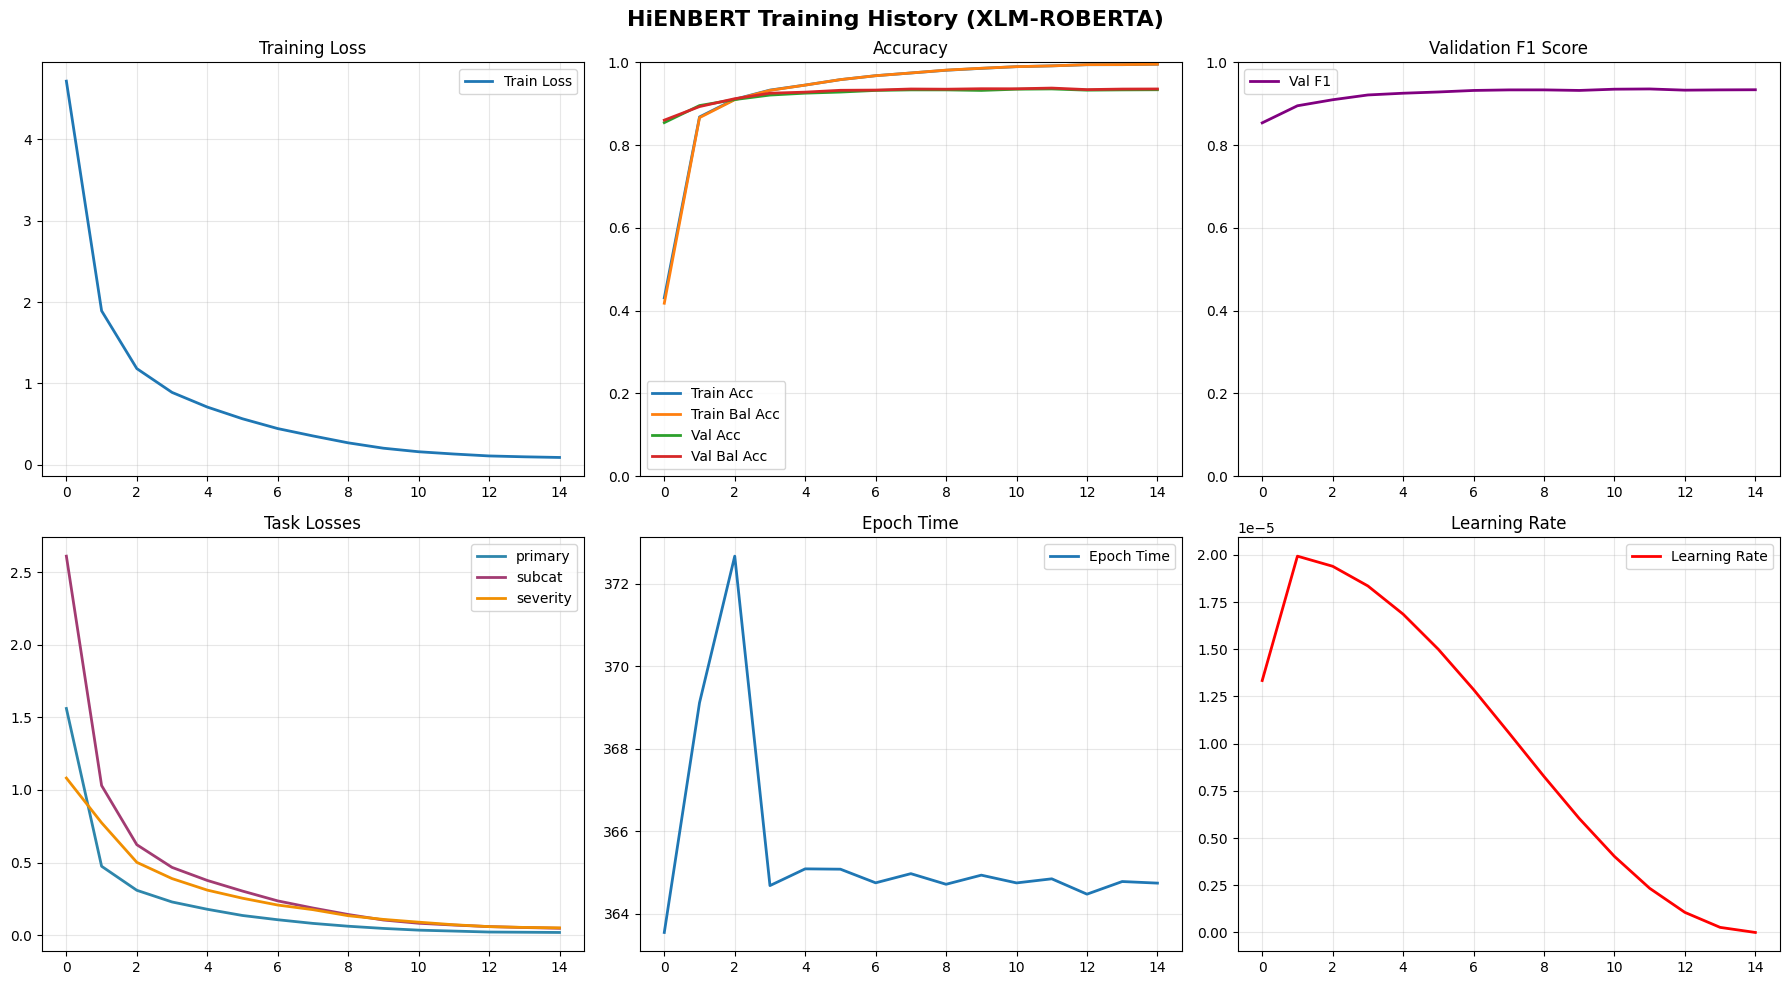

In [12]:
# ============================================================================
# CELL 12: TRAINING HISTORY VISUALIZATION
# ============================================================================

def plot_optimized_history(train_history, val_history, save_path=None):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Training loss
    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2)
    axes[0, 0].set_title('Training Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()
    
    # Accuracy
    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2)
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2)
    axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2)
    axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2)
    axes[0, 1].set_title('Accuracy')
    axes[0, 1].set_ylim(0, 1)
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    
    # F1 Score
    axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
    axes[0, 2].set_title('Validation F1 Score')
    axes[0, 2].set_ylim(0, 1)
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].legend()
    
    # Task losses
    task_names = ['primary', 'subcat', 'severity']
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task Losses')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Epoch time
    axes[1, 1].plot([h['time'] for h in train_history], label='Epoch Time', linewidth=2)
    axes[1, 1].set_title('Epoch Time')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    
    # Learning rate
    axes[1, 2].plot([h['lr'] for h in train_history], label='Learning Rate', linewidth=2, color='red')
    axes[1, 2].set_title('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()
    
    plt.suptitle(f'HiENBERT Training History ({Config.BASE_MODEL.upper()})', fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_optimized_history(train_history, val_history, save_path=f"{Config.VISUALIZATION_DIR}/training_history.png")

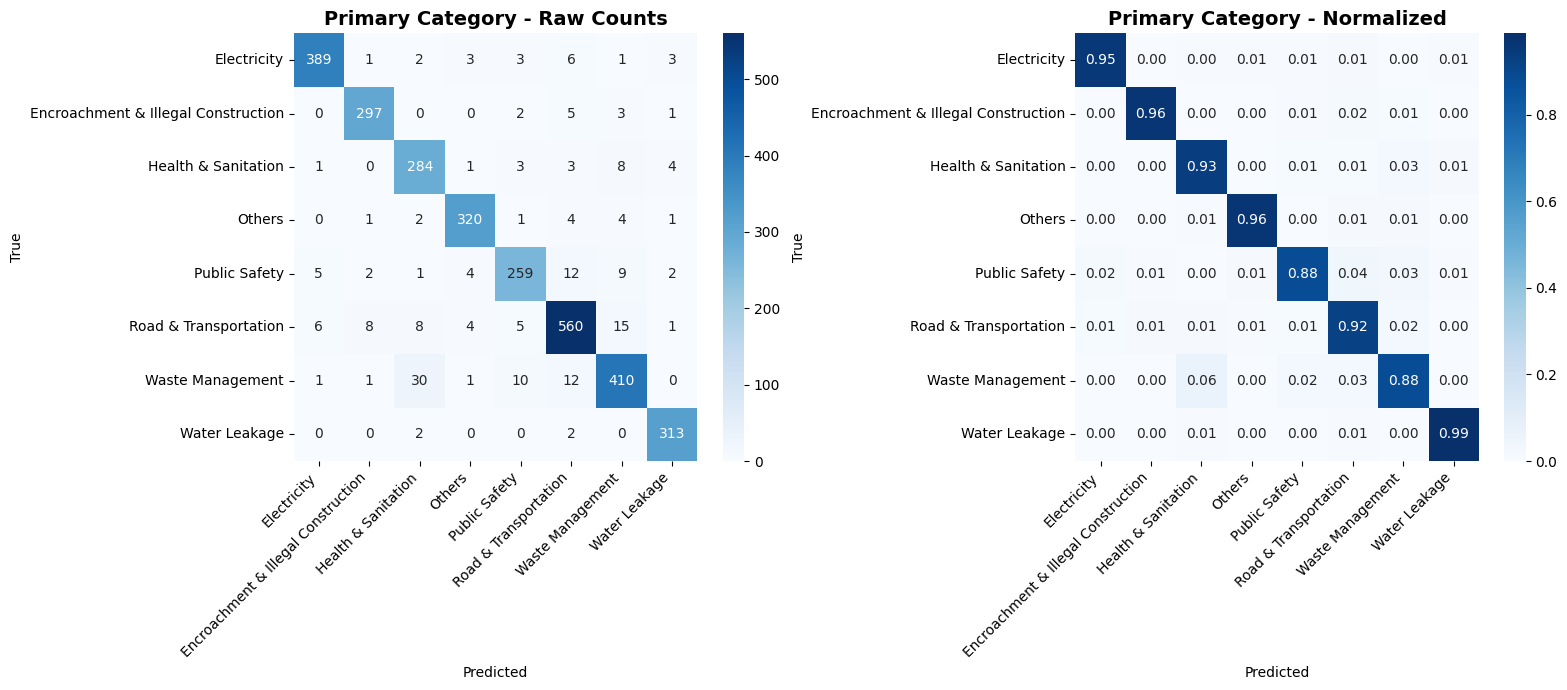

✅ Confusion matrix saved


In [13]:
# ============================================================================
# CELL 13: CONFUSION MATRIX
# ============================================================================

def plot_confusion_matrix_optimized(y_true, y_pred, class_names, title, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot confusion matrix
class_names = preprocessor.le_primary.classes_
plot_confusion_matrix_optimized(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

print(f"✅ Confusion matrix saved")

In [15]:
# ============================================================================
# CELL 15: OPTIMIZED ABLATION STUDY
# ============================================================================

class OptimizedAblationStudy:
    """Optimized ablation study with efficient evaluation"""
    
    def __init__(self, base_model, tokenizer, test_df, device):
        self.base_model = base_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.device = device
        self.results = {}
        
        self.model_config = {
            'n_primary': base_model.n_primary,
            'n_subcat': base_model.n_subcat,
            'n_severity': base_model.n_severity,
            'dropout': 0.2
        }
        
        self._prepare_test_data()
    
    def _prepare_test_data(self):
        class SimpleDataset(Dataset):
            def __init__(self, data, tokenizer, max_length=128):
                self.data = data.reset_index(drop=True)
                self.tokenizer = tokenizer
                self.max_length = max_length
            
            def __len__(self):
                return len(self.data)
            
            def __getitem__(self, idx):
                row = self.data.iloc[idx]
                text = str(row.get('text', ''))
                enc = self.tokenizer(
                    text,
                    truncation=True,
                    padding='max_length',
                    max_length=self.max_length,
                    return_tensors='pt'
                )
                return {
                    'input_ids': enc['input_ids'].squeeze(),
                    'attention_mask': enc['attention_mask'].squeeze(),
                    'primary': torch.tensor(row['primary_label'], dtype=torch.long),
                    'sentiment': torch.tensor(0.0, dtype=torch.float)
                }
        
        dataset = SimpleDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)
    
    def evaluate_model(self, model, description=""):
        model.eval()
        all_preds, all_labels = [], []
        
        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)
                
                p1, _, _ = model(input_ids, attention_mask, sentiment)
                preds = torch.argmax(p1, dim=1)
                
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(batch['primary'].cpu().numpy())
        
        return {
            'accuracy': accuracy_score(all_labels, all_preds),
            'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
            'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0)
        }
    
    def run_study(self):
        """Run ablation study with all variants"""
        print("\n" + "="*80)
        print("OPTIMIZED ABLATION STUDY")
        print("="*80)
        
        # Define model variants
        variants = {
            'baseline': OptimizedHiEnBERT,
            'no_dropout': lambda bm, np, ns, nsev: OptimizedHiEnBERT(bm, np, ns, nsev, dropout=0.0),
            'high_dropout': lambda bm, np, ns, nsev: OptimizedHiEnBERT(bm, np, ns, nsev, dropout=0.5),
            'no_shared': self._create_no_shared,
            'deeper_shared': self._create_deeper_shared
        }
        
        for name, builder in variants.items():
            print(f"\nEvaluating: {name}")
            model = builder(self.base_model.base, 
                          self.model_config['n_primary'],
                          self.model_config['n_subcat'],
                          self.model_config['n_severity'])
            model = model.to(self.device)
            
            metrics = self.evaluate_model(model, name)
            self.results[name] = metrics
            print(f"  F1: {metrics['f1_weighted']:.4f}, Acc: {metrics['accuracy']:.4f}")
        
        return self.results
    
    def _create_no_shared(self, base_model, n_primary, n_subcat, n_severity):
        class NoSharedModel(nn.Module):
            def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
                super().__init__()
                self.base = base_model
                hidden_size = base_model.config.hidden_size
                self.dropout = nn.Dropout(dropout)
                self.fc_primary = nn.Linear(hidden_size, n_primary)
                self.fc_subcat = nn.Linear(hidden_size, n_subcat)
                self.fc_severity = nn.Linear(hidden_size, n_severity)
                self.n_primary = n_primary
                self.n_subcat = n_subcat
                self.n_severity = n_severity
                self.hidden_size = hidden_size
            
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = self.dropout(cls)
                return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
        
        return NoSharedModel(base_model, n_primary, n_subcat, n_severity)
    
    def _create_deeper_shared(self, base_model, n_primary, n_subcat, n_severity):
        class DeeperSharedModel(nn.Module):
            def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
                super().__init__()
                self.base = base_model
                hidden_size = base_model.config.hidden_size
                self.shared = nn.Sequential(
                    nn.Linear(hidden_size, hidden_size),
                    nn.GELU(),
                    nn.Dropout(dropout),
                    nn.Linear(hidden_size, hidden_size),
                    nn.GELU(),
                    nn.Dropout(dropout)
                )
                self.fc_primary = nn.Linear(hidden_size, n_primary)
                self.fc_subcat = nn.Linear(hidden_size, n_subcat)
                self.fc_severity = nn.Linear(hidden_size, n_severity)
                self.n_primary = n_primary
                self.n_subcat = n_subcat
                self.n_severity = n_severity
                self.hidden_size = hidden_size
            
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = self.shared(cls)
                return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
        
        return DeeperSharedModel(base_model, n_primary, n_subcat, n_severity)
    
    def visualize_results(self, save_path=None):
        """Visualize ablation results"""
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        variants = list(self.results.keys())
        f1_values = [self.results[v]['f1_weighted'] for v in variants]
        acc_values = [self.results[v]['accuracy'] for v in variants]
        
        colors = ['#2E86AB', '#A23B72', '#F18F01', '#2E8B57', '#8B4513']
        
        # F1 Score
        bars = axes[0].bar(variants, f1_values, color=colors[:len(variants)])
        axes[0].axhline(y=self.results['baseline']['f1_weighted'], color='red', linestyle='--', label='Baseline')
        axes[0].set_ylim(0, 1)
        axes[0].set_title('F1 Score Comparison', fontsize=14, fontweight='bold')
        axes[0].set_ylabel('F1 Weighted Score')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3, axis='y')
        
        for bar, val in zip(bars, f1_values):
            axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                        f'{val:.4f}', ha='center', va='bottom', fontsize=9)
        
        # Accuracy
        bars = axes[1].bar(variants, acc_values, color=colors[:len(variants)])
        axes[1].axhline(y=self.results['baseline']['accuracy'], color='red', linestyle='--', label='Baseline')
        axes[1].set_ylim(0, 1)
        axes[1].set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
        axes[1].set_ylabel('Accuracy')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3, axis='y')
        
        for bar, val in zip(bars, acc_values):
            axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                        f'{val:.4f}', ha='center', va='bottom', fontsize=9)
        
        plt.suptitle(f'HiENBERT Ablation Study ({Config.BASE_MODEL.upper()})', 
                    fontsize=16, fontweight='bold')
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

# Run ablation study
print("\n" + "="*80)
print("STARTING OPTIMIZED ABLATION STUDY")
print("="*80)

try:
    ablation = OptimizedAblationStudy(
        model, tokenizer, test_df, Config.DEVICE
    )
    ablation_results = ablation.run_study()
    ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/ablation_study_results.png"
    )
    
    print("\n" + "="*80)
    print("ABLATION STUDY SUMMARY")
    print("="*80)
    baseline = ablation_results['baseline']['f1_weighted']
    for name, metrics in ablation_results.items():
        change = metrics['f1_weighted'] - baseline
        print(f"  {name}: {metrics['f1_weighted']:.4f} ({change:+.4f})")
        
except Exception as e:
    print(f"Error during ablation study: {e}")


STARTING OPTIMIZED ABLATION STUDY

OPTIMIZED ABLATION STUDY

Evaluating: baseline


Error during ablation study: Can't pickle local object 'OptimizedAblationStudy._prepare_test_data.<locals>.SimpleDataset'


In [18]:
# ============================================================================
# CELL 20: COMPLETE SUMMARY REPORT
# ============================================================================

def generate_summary_report():
    """Generate comprehensive summary report"""
    
    print("\n" + "="*80)
    print(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)")
    print("="*80)
    
    # 1. Dataset Statistics
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    # 2. Model Architecture
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.BASE_MODEL.upper()}")
    print(f"   Model Path: {get_model_path()}")
    print(f"   Hidden Size: {model.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    # # 3. Imbalance Handling
    # print("\n3. IMBALANCE HANDLING:")
    # print(f"   Class Weights: {Config.USE_CLASS_WEIGHTS}")
    # print(f"   Focal Loss: {Config.USE_FOCAL_LOSS}")
    # if Config.USE_FOCAL_LOSS:
    #     print(f"   Focal Alpha: {Config.FOCAL_ALPHA}")
    #     print(f"   Focal Gamma: {Config.FOCAL_GAMMA}")
    # print(f"   Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    # 4. Training Details
    print("\n4. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"   Mixed Precision: {Config.USE_AMP}")
    
    # 5. Test Performance
    print("\n5. TEST SET PERFORMANCE:")
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"   {metric}: {value:.4f}")
    
    # 6. Best Validation Performance
    print("\n6. BEST VALIDATION PERFORMANCE:")
    print(f"   Best Validation F1: {best_val_f1:.4f}")
    print(f"   Best Validation Balanced Accuracy: {best_val_balanced_acc:.4f}")
    
    # 7. Training History
    print("\n7. TRAINING HISTORY:")
    print(f"   Final Train Loss: {train_history[-1]['loss']:.4f}")
    print(f"   Final Train Accuracy: {train_history[-1]['acc']:.4f}")
    print(f"   Final Train Balanced Accuracy: {train_history[-1]['balanced_acc']:.4f}")
    
    # 8. Severity Distribution
    print("\n8. SEVERITY DISTRIBUTION (Training):")
    severity_dist = train_df['severity'].value_counts()
    severity_pct = train_df['severity'].value_counts(normalize=True) * 100
    for severity in ['LOW', 'MEDIUM', 'HIGH']:
        print(f"   {severity}: {severity_dist.get(severity, 0)} ({severity_pct.get(severity, 0):.1f}%)")
    
    # 9. Saved Files
    print("\n9. SAVED FILES:")
    print(f"   Best Model: {Config.MODEL_DIR}/best_hienbert_model.pt")
    print(f"   Final Model: {Config.MODEL_DIR}/hienbert_model.pt")
    print(f"   Encoders: {Config.MODEL_DIR}/le_*.pkl")
    print(f"   Test Results: {Config.RESULTS_DIR}/test_results.json")
    print(f"   Comparison Table: {Config.RESULTS_DIR}/model_comparison.csv")
    print(f"   Visualizations: {Config.VISUALIZATION_DIR}/")
    
    print("\n" + "="*80)
    print("END OF SUMMARY REPORT")
    print("="*80)
    
    # Save report to file
    with open(f"{Config.RESULTS_DIR}/summary_report.txt", 'w') as f:
        f.write(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)\n")
        f.write("="*80 + "\n\n")
        # Write all the above information to file
        # ... (similar content as printed)

# Generate summary report
generate_summary_report()

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results directory: {Config.RESULTS_DIR}")
print(f"📁 Visualizations directory: {Config.VISUALIZATION_DIR}")
print(f"📁 Models directory: {Config.MODEL_DIR}")
print(f"\n{'='*80}")
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print(f"Base Model: {Config.BASE_MODEL.upper()}")
print("="*80)


HIENBERT COMPREHENSIVE SUMMARY REPORT (XLM-ROBERTA Base)

1. DATASET STATISTICS:
   Training samples: 14165
   Validation samples: 3035
   Test samples: 3036
   Primary categories: 8
   Subcategories: 24
   Severity levels: 3

2. MODEL ARCHITECTURE:
   Base Model: XLM-ROBERTA
   Model Path: xlm-roberta-base
   Hidden Size: 768
   Total Parameters: 278,661,155
   Dropout Rate: 0.3
   Max Sequence Length: 128

4. TRAINING DETAILS:
   Epochs: 15
   Batch Size: 32
   Learning Rate: 2e-05
   Weight Decay: 0.01
   Mixed Precision: True

5. TEST SET PERFORMANCE:
   accuracy: 0.9328
   balanced_accuracy: 0.9357
   f1_macro: 0.9342
   f1_weighted: 0.9328
   precision: 0.9332
   recall: 0.9328
   cohen_kappa: 0.9224
   mcc: 0.9225

6. BEST VALIDATION PERFORMANCE:
   Best Validation F1: 0.9357
   Best Validation Balanced Accuracy: 0.9378

7. TRAINING HISTORY:
   Final Train Loss: 0.0912
   Final Train Accuracy: 0.9954
   Final Train Balanced Accuracy: 0.9954

8. SEVERITY DISTRIBUTION (Training):

In [ ]:
# ============================================================================
# COMPLETE LANGUAGE-WISE AND CLASS-WISE PERFORMANCE ANALYSIS
# ============================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, balanced_accuracy_score,
    cohen_kappa_score, matthews_corrcoef
)


# ============================================================================
# DATASET CLASSES
# ============================================================================

class LanguageWiseDataset(Dataset):
    """
    Dataset that uses a specific language column for evaluation.
    """
    def __init__(self, df, tokenizer, text_column, max_length=128):
        self.texts = df[text_column].fillna('').astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": torch.tensor(0.0, dtype=torch.float)
        }


class PreTokenizedEvalDataset(Dataset):
    """
    Pre-tokenized dataset for faster evaluation.
    """
    def __init__(self, df, tokenizer, max_length=128):
        print("Pre-tokenizing dataset for evaluation...")
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        
        texts = df["text"].astype(str).tolist()
        encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )
        self.input_ids = encodings["input_ids"]
        self.attention_mask = encodings["attention_mask"]
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        print(f"✅ Pre-tokenized {len(df)} samples")
    
    def __len__(self):
        return len(self.primary)
    
    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


# ============================================================================
# EVALUATION FUNCTIONS
# ============================================================================

def evaluate_task(model, dataloader, device, task='primary', return_predictions=False):
    """
    Evaluate model for a specific task.
    
    Args:
        model: The model to evaluate
        dataloader: DataLoader with evaluation data
        device: Device to run evaluation on
        task: 'primary', 'subcat', or 'severity'
        return_predictions: Whether to return predictions and labels
    
    Returns:
        Dictionary of metrics and optionally predictions
    """
    model.eval()
    
    task_map = {
        'primary': 0,  # Output index for primary
        'subcat': 1,   # Output index for subcat
        'severity': 2  # Output index for severity
    }
    
    if task not in task_map:
        raise ValueError(f"Task must be 'primary', 'subcat', or 'severity', got {task}")
    
    output_idx = task_map[task]
    
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f'Evaluating {task}', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            # Get all outputs
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            outputs = [p1, p2, p3]
            
            # Select the appropriate output
            logits = outputs[output_idx]
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
            
            # Get labels
            if task == 'primary':
                labels = batch['primary']
            elif task == 'subcat':
                labels = batch['subcat']
            else:
                labels = batch['severity']
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'support': len(all_labels),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics


def get_class_wise_metrics(labels, preds, class_names=None):
    """
    Get per-class metrics.
    """
    report = classification_report(
        labels, preds,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    
    class_metrics = []
    for name in class_names:
        if name in report:
            metrics = report[name]
            class_metrics.append({
                'class': name,
                'precision': metrics.get('precision', 0),
                'recall': metrics.get('recall', 0),
                'f1_score': metrics.get('f1-score', 0),
                'support': metrics.get('support', 0)
            })
    
    return pd.DataFrame(class_metrics)


# ============================================================================
# LANGUAGE-WISE ANALYSIS
# ============================================================================

def analyze_language_performance(model, test_df, tokenizer, device, 
                                  class_names=None, batch_size=32):
    """
    Analyze model performance by language and by task.
    
    Args:
        model: The trained model
        test_df: Test dataframe with language columns (text_en, Hindi, Hinglish)
        tokenizer: Tokenizer
        device: Device
        class_names: List of class names for primary categories
        batch_size: Batch size for evaluation
    
    Returns:
        Dictionary with comprehensive performance results
    """
    print("\n" + "="*80)
    print("COMPREHENSIVE LANGUAGE-WISE AND CATEGORY-WISE ANALYSIS")
    print("="*80)
    
    # Language columns mapping
    language_columns = {
        'English': 'text_en',
        'Hindi': 'Hindi',
        'Hinglish': 'Hinglish'
    }
    
    results = {
        'language_performance': {},
        'task_performance': {},
        'predictions': {}
    }
    
    # ========================================================================
    # 1. LANGUAGE-WISE PERFORMANCE
    # ========================================================================
    
    print("\n" + "-"*80)
    print("LANGUAGE-WISE PERFORMANCE")
    print("-"*80)
    
    for lang_name, col_name in language_columns.items():
        print(f"\n📊 Evaluating: {lang_name}")
        
        # Filter samples with non-empty text for this language
        lang_df = test_df[
            test_df[col_name].notna() & 
            (test_df[col_name].astype(str).str.strip() != '')
        ].copy()
        
        if len(lang_df) == 0:
            print(f"   ⚠️ No samples found for {lang_name}")
            results['language_performance'][lang_name] = {'error': 'No samples'}
            continue
        
        # Create dataset using the specific language column
        dataset = LanguageWiseDataset(lang_df, tokenizer, col_name, Config.MAX_LENGTH)
        loader = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )
        
        # Evaluate all tasks
        lang_metrics = {}
        
        for task in ['primary', 'subcat', 'severity']:
            metrics = evaluate_task(model, loader, device, task=task)
            lang_metrics[task] = metrics
        
        results['language_performance'][lang_name] = lang_metrics
        
        # Print summary
        print(f"   Samples: {len(lang_df)}")
        print(f"   Primary  - Acc: {lang_metrics['primary']['accuracy']:.4f}, F1-W: {lang_metrics['primary']['f1_weighted']:.4f}")
        print(f"   Subcat   - Acc: {lang_metrics['subcat']['accuracy']:.4f}, F1-W: {lang_metrics['subcat']['f1_weighted']:.4f}")
        print(f"   Severity - Acc: {lang_metrics['severity']['accuracy']:.4f}, F1-W: {lang_metrics['severity']['f1_weighted']:.4f}")
    
    # ========================================================================
    # 2. OVERALL TASK PERFORMANCE (using combined text)
    # ========================================================================
    
    print("\n" + "-"*80)
    print("OVERALL TASK PERFORMANCE (Combined Text)")
    print("-"*80)
    
    # Create dataset with combined text
    eval_dataset = PreTokenizedEvalDataset(test_df, tokenizer, Config.MAX_LENGTH)
    eval_loader = DataLoader(
        eval_dataset,
        batch_size=batch_size * 2,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )
    
    # Evaluate each task
    for task in ['primary', 'subcat', 'severity']:
        metrics, preds, labels = evaluate_task(
            model, eval_loader, device, task=task, return_predictions=True
        )
        results['task_performance'][task] = metrics
        results['predictions'][task] = {'preds': preds, 'labels': labels}
    
    # Print summary table
    print("\nOverall Performance:")
    print("-" * 100)
    print(f"{'Task':<12} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12}")
    print("-" * 100)
    for task in ['primary', 'subcat', 'severity']:
        m = results['task_performance'][task]
        print(f"{task.upper():<12} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}")
    
    # ========================================================================
    # 3. CLASS-WISE PERFORMANCE (Primary)
    # ========================================================================
    
    print("\n" + "-"*80)
    print("CLASS-WISE PERFORMANCE (Primary Categories)")
    print("-"*80)
    
    if class_names is not None:
        primary_preds = results['predictions']['primary']['preds']
        primary_labels = results['predictions']['primary']['labels']
        
        class_df = get_class_wise_metrics(primary_labels, primary_preds, class_names)
        
        print("\nPer-Class Performance:")
        print("-" * 80)
        print(f"{'Category':<30} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Support':<10}")
        print("-" * 80)
        for _, row in class_df.iterrows():
            print(f"{row['class']:<30} {row['precision']:.4f}     {row['recall']:.4f}     {row['f1_score']:.4f}     {row['support']:.0f}")
        
        results['class_performance'] = class_df.to_dict('records')
    
    # ========================================================================
    # 4. LANGUAGE × TASK CROSS-ANALYSIS
    # ========================================================================
    
    print("\n" + "-"*80)
    print("LANGUAGE × TASK CROSS-ANALYSIS (F1-Weighted)")
    print("-"*80)
    
    print("\n" + "="*100)
    print(f"{'Language':<12} {'Primary Acc':<14} {'Primary F1':<14} {'Subcat Acc':<14} {'Subcat F1':<14} {'Sev Acc':<14} {'Sev F1':<14}")
    print("="*100)
    
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            print(f"{lang:<12} {metrics['primary']['accuracy']:.4f}     {metrics['primary']['f1_weighted']:.4f}     {metrics['subcat']['accuracy']:.4f}     {metrics['subcat']['f1_weighted']:.4f}     {metrics['severity']['accuracy']:.4f}     {metrics['severity']['f1_weighted']:.4f}")
    
    return results

In [ ]:
# ============================================================================
# VISUALIZATION
# ============================================================================

def visualize_performance(results, class_names=None, save_path=None):
    """
    Create comprehensive visualizations for performance analysis.
    """
    fig, axes = plt.subplots(2, 3, figsize=(22, 12))
    
    # Color palette
    colors = {'primary': '#2E86AB', 'subcat': '#A23B72', 'severity': '#F18F01'}
    
    # ========================================================================
    # 1. Language-wise F1 Scores by Task
    # ========================================================================
    ax = axes[0, 0]
    languages = []
    primary_f1, subcat_f1, severity_f1 = [], [], []
    
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            languages.append(lang)
            primary_f1.append(metrics['primary']['f1_weighted'])
            subcat_f1.append(metrics['subcat']['f1_weighted'])
            severity_f1.append(metrics['severity']['f1_weighted'])
    
    if languages:
        x = np.arange(len(languages))
        width = 0.25
        
        bars1 = ax.bar(x - width, primary_f1, width, label='Primary', color=colors['primary'], alpha=0.8)
        bars2 = ax.bar(x, subcat_f1, width, label='Subcat', color=colors['subcat'], alpha=0.8)
        bars3 = ax.bar(x + width, severity_f1, width, label='Severity', color=colors['severity'], alpha=0.8)
        
        for bars in [bars1, bars2, bars3]:
            for bar in bars:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                       f'{height:.3f}', ha='center', va='bottom', fontsize=9)
        
        ax.set_xlabel('Language', fontsize=12)
        ax.set_ylabel('F1 Score (Weighted)', fontsize=12)
        ax.set_title('Language-wise Performance by Task', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(languages)
        ax.set_ylim(0, 1.05)
        ax.legend(loc='upper right')
        ax.grid(True, alpha=0.3, axis='y')
    
    # ========================================================================
    # 2. Language-wise Accuracy
    # ========================================================================
    ax = axes[0, 1]
    if languages:
        primary_acc = [results['language_performance'][lang]['primary']['accuracy'] for lang in languages]
        subcat_acc = [results['language_performance'][lang]['subcat']['accuracy'] for lang in languages]
        severity_acc = [results['language_performance'][lang]['severity']['accuracy'] for lang in languages]
        
        x = np.arange(len(languages))
        width = 0.25
        
        bars1 = ax.bar(x - width, primary_acc, width, label='Primary', color=colors['primary'], alpha=0.8)
        bars2 = ax.bar(x, subcat_acc, width, label='Subcat', color=colors['subcat'], alpha=0.8)
        bars3 = ax.bar(x + width, severity_acc, width, label='Severity', color=colors['severity'], alpha=0.8)
        
        for bars in [bars1, bars2, bars3]:
            for bar in bars:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                       f'{height:.3f}', ha='center', va='bottom', fontsize=9)
        
        ax.set_xlabel('Language', fontsize=12)
        ax.set_ylabel('Accuracy', fontsize=12)
        ax.set_title('Language-wise Accuracy by Task', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(languages)
        ax.set_ylim(0, 1.05)
        ax.legend(loc='upper right')
        ax.grid(True, alpha=0.3, axis='y')
    
    # ========================================================================
    # 3. Overall Task Performance
    # ========================================================================
    ax = axes[0, 2]
    tasks = ['Primary', 'Subcat', 'Severity']
    task_keys = ['primary', 'subcat', 'severity']
    metrics_to_plot = ['accuracy', 'f1_weighted', 'precision', 'recall']
    
    x = np.arange(len(tasks))
    width = 0.2
    metric_colors = ['#1B5E20', '#2E86AB', '#E67E22', '#8E44AD']
    
    for i, (metric, color) in enumerate(zip(metrics_to_plot, metric_colors)):
        values = [results['task_performance'][k][metric] for k in task_keys]
        bars = ax.bar(x + (i - 1.5) * width, values, width, 
                     label=metric.capitalize(), color=color, alpha=0.7)
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f'{height:.3f}', ha='center', va='bottom', fontsize=7)
    
    ax.set_xlabel('Task', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title('Overall Performance by Task', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(tasks)
    ax.set_ylim(0, 1.05)
    ax.legend(loc='upper right', ncol=2)
    ax.grid(True, alpha=0.3, axis='y')
    
    # ========================================================================
    # 4. Language Support (Sample Counts)
    # ========================================================================
    ax = axes[1, 0]
    support_counts = []
    for lang in languages:
        support = results['language_performance'][lang]['primary']['support']
        support_counts.append(support)
    
    bars = ax.bar(languages, support_counts, color='#2E86AB', edgecolor='black', alpha=0.8)
    ax.set_xlabel('Language', fontsize=12)
    ax.set_ylabel('Number of Samples', fontsize=12)
    ax.set_title('Test Samples by Language', fontsize=14, fontweight='bold')
    for bar, v in zip(bars, support_counts):
        ax.text(bar.get_x() + bar.get_width()/2., v + 5, str(v), 
               ha='center', va='bottom', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    
    # ========================================================================
    # 5. Language-wise Kappa & MCC (Primary)
    # ========================================================================
    ax = axes[1, 1]
    if languages:
        primary_kappa = [results['language_performance'][lang]['primary']['cohen_kappa'] for lang in languages]
        primary_mcc = [results['language_performance'][lang]['primary']['mcc'] for lang in languages]
        
        x = np.arange(len(languages))
        width = 0.35
        
        bars1 = ax.bar(x - width/2, primary_kappa, width, label="Cohen's Kappa", color='#2E86AB', alpha=0.8)
        bars2 = ax.bar(x + width/2, primary_mcc, width, label='MCC', color='#A23B72', alpha=0.8)
        
        for bars in [bars1, bars2]:
            for bar in bars:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                       f'{height:.3f}', ha='center', va='bottom', fontsize=9)
        
        ax.set_xlabel('Language', fontsize=12)
        ax.set_ylabel('Score', fontsize=12)
        ax.set_title('Primary Task - Kappa & MCC by Language', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(languages)
        ax.set_ylim(0, 1.05)
        ax.legend(loc='upper right')
        ax.grid(True, alpha=0.3, axis='y')
    
    # ========================================================================
    # 6. Class-wise Performance (Primary) - Top 10
    # ========================================================================
    ax = axes[1, 2]
    
    if class_names is not None and 'class_performance' in results:
        class_df = pd.DataFrame(results['class_performance'])
        class_df = class_df.sort_values('f1_score', ascending=True)
        
        # Show top 10 classes
        if len(class_df) > 10:
            class_df = class_df.tail(10)
        
        y_pos = np.arange(len(class_df))
        ax.barh(y_pos, class_df['f1_score'], color='#2E86AB', alpha=0.8)
        
        ax.set_yticks(y_pos)
        ax.set_yticklabels(class_df['class'], fontsize=9)
        ax.set_xlabel('F1 Score', fontsize=12)
        ax.set_title('Top 10 Categories by F1 Score', fontsize=14, fontweight='bold')
        ax.set_xlim(0, 1.05)
        ax.grid(True, alpha=0.3, axis='x')
        
        for i, (_, row) in enumerate(class_df.iterrows()):
            ax.text(row['f1_score'] + 0.01, i, f"{row['f1_score']:.3f}", 
                   va='center', fontsize=9)
    
    plt.suptitle(f'Comprehensive Performance Analysis - {Config.BASE_MODEL.upper()}', 
                fontsize=18, fontweight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Visualization saved: {save_path}")
    
    return fig

In [ ]:
# ============================================================================
# SUMMARY REPORT
# ============================================================================

def print_summary(results):
    """
    Print comprehensive summary of performance results.
    """
    print("\n" + "="*80)
    print(f"FINAL SUMMARY REPORT - {Config.BASE_MODEL.upper()}")
    print("="*80)
    
    # Task Performance Summary
    print("\n📊 OVERALL TASK PERFORMANCE:")
    print("-" * 80)
    print(f"{'Task':<12} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Kappa':<12}")
    print("-" * 80)
    for task in ['primary', 'subcat', 'severity']:
        m = results['task_performance'][task]
        print(f"{task.upper():<12} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['cohen_kappa']:.4f}")
    
    # Language-wise Summary
    print("\n📊 LANGUAGE-WISE PERFORMANCE (Primary Task):")
    print("-" * 80)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Weighted':<14} {'Kappa':<12}")
    print("-" * 80)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['primary']
            print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_weighted']:.4f}       {m['cohen_kappa']:.4f}")
    
    # Averages
    lang_metrics = [m for m in results['language_performance'].values() if 'error' not in m]
    if lang_metrics:
        avg_primary = np.mean([m['primary']['f1_weighted'] for m in lang_metrics])
        avg_subcat = np.mean([m['subcat']['f1_weighted'] for m in lang_metrics])
        avg_severity = np.mean([m['severity']['f1_weighted'] for m in lang_metrics])
        
        print(f"\n📊 AVERAGE F1-WEIGHTED BY LANGUAGE:")
        print(f"  Primary:  {avg_primary:.4f}")
        print(f"  Subcat:   {avg_subcat:.4f}")
        print(f"  Severity: {avg_severity:.4f}")
    
    # Best Performing
    best_lang = max([(lang, results['language_performance'][lang]['primary']['f1_weighted'])
                    for lang in results['language_performance'] 
                    if 'error' not in results['language_performance'][lang]], 
                    key=lambda x: x[1])
    print(f"\n🏆 BEST PERFORMING LANGUAGE: {best_lang[0]} (Primary F1: {best_lang[1]:.4f})")
    
    best_task = max([(task, results['task_performance'][task]['f1_weighted'])
                    for task in ['primary', 'subcat', 'severity']], 
                    key=lambda x: x[1])
    print(f"🏆 BEST PERFORMING TASK: {best_task[0]} (F1: {best_task[1]:.4f})")
    
    print("\n" + "="*80)
    print(f"✅ {Config.BASE_MODEL.upper()} ANALYSIS COMPLETE!")
    print("="*80)

In [20]:
# ============================================================================
# MAIN EXECUTION
# ============================================================================

print("\n" + "="*80)
print("STARTING COMPREHENSIVE PERFORMANCE ANALYSIS")
print("="*80)

# Check required variables
required_vars = ['model', 'test_df', 'tokenizer', 'Config', 'preprocessor', 'class_names']
missing = [v for v in required_vars if v not in locals()]
if missing:
    print(f"⚠️ Missing required variables: {missing}")
    print("Please ensure the model is loaded and data is prepared.")

# Run the analysis
if 'model' in locals() and 'test_df' in locals():
    performance_results = analyze_language_performance(
        model=model,
        test_df=test_df,
        tokenizer=tokenizer,
        device=Config.DEVICE,
        class_names=class_names,
        batch_size=Config.BATCH_SIZE
    )
    
    # Visualize results
    visualize_performance(
        results=performance_results,
        class_names=class_names,
        save_path=f"{Config.VISUALIZATION_DIR}/language_category_performance.png"
    )
    
    # Print summary
    print_summary(performance_results)
    
    # Save results
    try:
        with open(f"{Config.RESULTS_DIR}/language_category_performance.json", "w", encoding='utf-8') as f:
            # Convert numpy types for JSON serialization
            def convert_to_serializable(obj):
                if isinstance(obj, np.ndarray):
                    return obj.tolist()
                elif isinstance(obj, (np.int64, np.int32)):
                    return int(obj)
                elif isinstance(obj, (np.float64, np.float32)):
                    return float(obj)
                elif isinstance(obj, dict):
                    return {k: convert_to_serializable(v) for k, v in obj.items()}
                elif isinstance(obj, list):
                    return [convert_to_serializable(item) for item in obj]
                else:
                    return obj
            
            serializable = convert_to_serializable(performance_results)
            json.dump(serializable, f, indent=2, ensure_ascii=False)
        print(f"\n✅ Results saved to: {Config.RESULTS_DIR}/language_category_performance.json")
    except Exception as e:
        print(f"⚠️ Could not save JSON results: {e}")